# RQ2 Full component grid analysis

**Research question** What is the contribution of pattern based detection, GLiNER, layout aware zoning, OCR, and cross region linking to reducing residual leakage compared with a text only baseline.

This notebook evaluates RQ2 with a full component grid. It tests pattern based detection, GLiNER, layout aware zoning, OCR, and cross region linking.

The main privacy metric is **severity weighted residual leakage**. Precision, recall and F1 are used to explain the detection quality and utility trade off.


In [2]:

import importlib
import itertools
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 170,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

DIRECT_LABELS = ("FULL_NAME", "FIRST_NAME", "LAST_NAME", "Student number", "Institutional email")
QUASI_LABELS = ("Course code", "Group label", "Programme", "Date", "Role")
LABELS = (*DIRECT_LABELS, *QUASI_LABELS)
REGIONS = ("cover", "header", "footer", "body", "body_table", "ocr")

LABEL_DISPLAY = {
    "FULL_NAME": "Full name",
    "FIRST_NAME": "First name",
    "LAST_NAME": "Last name",
    "Student number": "Student no.",
    "Institutional email": "Inst. email",
    "Course code": "Course code",
    "Group label": "Group label",
    "Programme": "Programme",
    "Date": "Date",
    "Role": "Role",
}

REGION_DISPLAY = {
    "cover": "Cover",
    "header": "Header",
    "footer": "Footer",
    "body": "Body text",
    "body_table": "Body table",
    "ocr": "Image/OCR",
}

PALETTE = {
    "precision": "#0072B2",
    "recall": "#009E73",
    "f1": "#D55E00",
    "leakage": "#CC79A7",
    "remaining": "#E69F00",
    "delta": "#56B4E9",
    "direct": "#0072B2",
    "quasi": "#E69F00",
    "region": "#4E79A7",
}


AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
def find_repo_root():
    cwd = Path.cwd().resolve()
    for p in [cwd, *cwd.parents]:
        if (p / "document_generator").exists() and (p / "thesis_project").exists():
            return p
    return cwd


ROOT = find_repo_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from thesis_project.dataset import DatasetManager
from thesis_project.experiments import Experiments
from thesis_project.evaluation import Evaluation, _metrics
from thesis_project.shared import Config, canon, direct, severity_weight_for
import thesis_project.defender.name_model as name_model

WORK_DIR = ROOT / "notebooks" / "workspace"
# Prefer the notebook workspace dataset when it exists
CANDIDATE_WORKSPACE_DATASET = Path("notebooks") / "workspace" / "dataset"
if CANDIDATE_WORKSPACE_DATASET.exists():
    DATASET_ROOT = CANDIDATE_WORKSPACE_DATASET.resolve()
else:
    DATASET_ROOT = WORK_DIR / "dataset"
MODEL_PATH = WORK_DIR / "tuned_models" / "name_candidate_model.joblib"
GLINER_CACHE_DIR = WORK_DIR / "gliner_cache"

WORK_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
GLINER_CACHE_DIR.mkdir(parents=True, exist_ok=True)

HAS_EASYOCR = importlib.util.find_spec("easyocr") is not None
HAS_GLINER = importlib.util.find_spec("gliner") is not None

print(f"Repository root {ROOT}")
print(f"Dataset root {DATASET_ROOT}")
print(f"GLiNER cache dir {GLINER_CACHE_DIR}")
print(f"Optional packages easyocr={HAS_EASYOCR}, gliner={HAS_GLINER}")

Repository root thesis-1
Dataset root notebooks\workspace\dataset
GLiNER cache dir notebooks\workspace\gliner_cache
Optional packages easyocr=True, gliner=True


In [4]:
def split_records(records):
    return {
        "train": [r for r in records if r.split == "train"],
        "val": [r for r in records if r.split == "val"],
        "test": [r for r in records if r.split == "test"],
    }


def build_train_df(dm, records):
    frames = []
    for rec in records:
        doc = dm.attach(rec)
        ann = dm.load_annotations(doc)
        names = {
            (e["path"], int(e["start"]), int(e["end"]), e["surface"]): 1
            for e in ann.get("text_entities", [])
            if canon(e.get("label", "")) == "FULL_NAME"
        }
        df = name_model.frame(doc.blocks, names, doc=doc.doc_id)
        if not df.empty:
            df["doc_id"] = doc.doc_id
            frames.append(df)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def ensure_candidate_model(dm, records):
    if MODEL_PATH.exists():
        return MODEL_PATH

    from sklearn.feature_extraction import DictVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import f1_score, make_scorer
    from sklearn.model_selection import GridSearchCV, GroupKFold
    from sklearn.pipeline import Pipeline
    import joblib

    train_df = build_train_df(dm, split_records(records)["train"])
    exclude = {"label", "doc_id", "path", "region", "surface", "start", "end", "template_id", "split"}
    feature_columns = [c for c in train_df.columns if c not in exclude]

    pipe = Pipeline([
        ("vectorizer", DictVectorizer(sparse=True)),
        ("classifier", LogisticRegression(max_iter=1500, solver="liblinear", random_state=42)),
    ])
    grid = {
        "classifier__C": [0.05, 0.1, 0.3, 1.0, 3.0, 10.0],
        "classifier__class_weight": [None, "balanced"],
        "classifier__penalty": ["l2"],
    }

    gs = GridSearchCV(
        pipe,
        grid,
        scoring=make_scorer(f1_score, zero_division=0),
        cv=GroupKFold(n_splits=min(5, train_df["doc_id"].nunique())),
        n_jobs=1,
        refit=True,
    )
    gs.fit(train_df[feature_columns].to_dict(orient="records"), train_df["label"].astype(int), groups=train_df["doc_id"])

    joblib.dump({
        "pipeline": gs.best_estimator_,
        "feature_columns": feature_columns,
        "cv_best_f1": float(gs.best_score_),
        "model_type": "logistic_regression_name_candidate_classifier",
    }, MODEL_PATH)

    return MODEL_PATH


def reference_table(dm, docs):
    rows = []
    for rec in docs:
        ann = dm.load_annotations(dm.attach(rec))
        for key, source in [("text_entities", "document text"), ("ocr_entities", "embedded image/OCR")]:
            for e in ann.get(key, []):
                label = canon(e.get("label", ""))
                rows.append({
                    "doc_id": rec.doc_id,
                    "template_id": rec.template_id,
                    "source": source,
                    "region": REGION_DISPLAY.get(e.get("region", ""), e.get("region", "")),
                    "label": LABEL_DISPLAY.get(label, label),
                    "class": "direct" if direct(label) else "quasi",
                    "severity_weight": severity_weight_for(label),
                })
    if rows:
        return pd.DataFrame(rows)
    else:
        return pd.DataFrame(columns=["doc_id", "template_id", "source", "region", "label", "class", "severity_weight"])


def oracle_result(dm, docs, cfg):
    exp = Experiments(DATASET_ROOT, cfg)
    labels = exp._labels(cfg)
    evaluator = Evaluation()
    rows = []
    for rec in docs:
        doc = dm.attach(rec)
        ann = dm.load_annotations(doc)
        pred = list(ann.get("text_entities", [])) + list(ann.get("ocr_entities", []))
        rows.append({
            "doc_id": rec.doc_id,
            "template_id": rec.template_id,
            "split": rec.split,
            "scores": evaluator.scores(ann, pred),
            "remaining_entities": evaluator.remain(ann, pred, labels),
            "predicted_entities": pred,
        })
    return exp._sum(rows, labels)


def bool_code(value, true_letter, false_letter="-"):
    return true_letter if bool(value) else false_letter


def combo_code(patterns, ner, layout, ocr, link):
    return " | ".join([
        bool_code(patterns, "P"),
        bool_code(ner, "G"),
        bool_code(layout, "L"),
        bool_code(ocr, "O"),
        bool_code(link, "X"),
    ])


def combo_name(patterns, ner, layout, ocr, link):
    return " + ".join([
        "Patterns" if patterns else "No patterns",
        "GLiNER" if ner else "No GLiNER",
        "Layout" if layout else "Body only",
        "OCR" if ocr else "No OCR",
        "Linking" if link else "No linking",
    ])


def build_grid_config(run_name, *, patterns=True, ner=True, layout=True, ocr=True, link=True):
    return Config(
        patterns=bool(patterns),
        ner=bool(ner),
        ocr=bool(ocr and HAS_EASYOCR),
        link=bool(link),
        strict=True,
        direct=True,
        quasi=True,
        labels=QUASI_LABELS,
        regions=() if layout else ("body",),
        pdf=False,
        candidate=str(model_path) if model_path else None,
        ner_backend="hybrid",
        gliner_model="urchade/gliner_multi-v2.1",
        gliner_threshold=0.35,
        fallback=True,
    )


def result_to_row(spec, result):
    m = result.get("overall", {})
    leakage = result.get("leakage", {})
    by_region = result.get("by_region", {})

    ocr_counts = by_region.get("ocr", {})
    ocr_tp = int(ocr_counts.get("tp", 0))
    ocr_fp = int(ocr_counts.get("fp", 0))
    ocr_fn = int(ocr_counts.get("fn", 0))

    ocr_precision = ocr_tp / (ocr_tp + ocr_fp) if (ocr_tp + ocr_fp) else 0
    ocr_recall = ocr_tp / (ocr_tp + ocr_fn) if (ocr_tp + ocr_fn) else 0
    ocr_f1 = (
        2 * ocr_precision * ocr_recall / (ocr_precision + ocr_recall)
        if (ocr_precision + ocr_recall)
        else 0
    )

    return {
        **spec,
        "correctly_detected": int(m.get("tp", 0)),
        "extra_redactions": int(m.get("fp", 0)),
        "remaining_reference_mentions": int(
            leakage.get("protected_remaining", leakage.get("total_mentions", m.get("fn", 0)))
        ),
        "precision": float(m.get("precision", 0)),
        "recall": float(m.get("recall", 0)),
        "f1": float(m.get("f1", 0)),
        "severity_weighted_residual_leakage": float(
            leakage.get("protected_weighted_total", leakage.get("weighted_total", 0))
        ),
        "ocr_precision": ocr_precision,
        "ocr_recall": ocr_recall,
        "ocr_f1": ocr_f1,
        "ocr_remaining_reference_mentions": ocr_fn,
    }


def result_to_region_label_rows(spec, result):
    rows = []
    for raw_region, label_map in result.get("by_region_label", {}).items():
        for raw_label, counts in label_map.items():
            fn = int(counts.get("fn", 0))
            rows.append({
                **spec,
                "region": REGION_DISPLAY.get(raw_region, raw_region),
                "label": LABEL_DISPLAY.get(raw_label, raw_label),
                "class": "direct" if direct(raw_label) else "quasi",
                "remaining_reference_mentions": fn,
                "severity_weighted_residual_leakage": fn * severity_weight_for(raw_label),
            })
    return rows


In [5]:

def run_full_component_grid():
    combinations = list(itertools.product([False, True], repeat=5))
    rows = []
    detail_rows = []

    pbar = tqdm(combinations, desc="Running RQ2 full component grid", unit="config")

    for patterns, ner, layout, ocr, link in pbar:
        effective_ocr = bool(ocr and HAS_EASYOCR)
        code = combo_code(patterns, ner, layout, effective_ocr, link)
        name = combo_name(patterns, ner, layout, effective_ocr, link)

        pbar.set_postfix_str(code)

        spec = {
            "code": code,
            "variant": name,
            "patterns": bool(patterns),
            "ner": bool(ner),
            "layout": bool(layout),
            "ocr": bool(effective_ocr),
            "link": bool(link),
        }

        cfg = build_grid_config(
            f"grid_{code}",
            patterns=patterns,
            ner=ner,
            layout=layout,
            ocr=effective_ocr,
            link=link,
        )

        exp_variant = Experiments(DATASET_ROOT, cfg)
        result = exp_variant.rq1()

        rows.append(result_to_row(spec, result))
        detail_rows.extend(result_to_region_label_rows(spec, result))

    grid = pd.DataFrame(rows)

    text_only_mask = (
        (grid["patterns"] == True) &
        (grid["ner"] == True) &
        (grid["layout"] == False) &
        (grid["ocr"] == False) &
        (grid["link"] == False)
    )

    if text_only_mask.any():
        baseline_leakage = float(grid.loc[text_only_mask, "severity_weighted_residual_leakage"].iloc[0])
    else:
        baseline_leakage = float(grid["severity_weighted_residual_leakage"].max())

    grid["leakage_reduction_vs_text_only_percent"] = np.where(
        baseline_leakage > 0,
        100 * (baseline_leakage - grid["severity_weighted_residual_leakage"]) / baseline_leakage,
        0,
    )

    grid = grid.sort_values("severity_weighted_residual_leakage", ascending=True).reset_index(drop=True)
    detail = pd.DataFrame(detail_rows)

    return grid, detail


COMPONENTS = {
    "patterns": "Pattern-based detection",
    "ner": "GLiNER",
    "layout": "Layout-aware zoning",
    "ocr": "OCR",
    "link": "Cross-region linking",
}


def component_pair_effects(grid_df):
    rows = []
    component_cols = ["patterns", "ner", "layout", "ocr", "link"]

    for component in component_cols:
        other_cols = [c for c in component_cols if c != component]
        off_rows = grid_df[grid_df[component] == False]

        for _, off in off_rows.iterrows():
            mask = grid_df[component] == True
            for col in other_cols:
                mask &= grid_df[col] == off[col]

            match = grid_df[mask]
            if match.empty:
                continue

            on = match.iloc[0]

            rows.append({
                "component": COMPONENTS[component],
                "comparison": f"{off['code']} → {on['code']}",
                "off_code": off["code"],
                "on_code": on["code"],
                "leakage_reduction": off["severity_weighted_residual_leakage"] - on["severity_weighted_residual_leakage"],
                "remaining_mentions_reduction": off["remaining_reference_mentions"] - on["remaining_reference_mentions"],
                "extra_redactions_change": on["extra_redactions"] - off["extra_redactions"],
                "precision_change": on["precision"] - off["precision"],
                "recall_change": on["recall"] - off["recall"],
                "f1_change": on["f1"] - off["f1"],
            })

    return pd.DataFrame(rows)


def component_effect_summary(effect_pairs_df):
    return (
        effect_pairs_df
        .groupby("component", as_index=False)
        .agg(
            matched_pairs=("comparison", "count"),
            mean_leakage_reduction=("leakage_reduction", "mean"),
            median_leakage_reduction=("leakage_reduction", "median"),
            max_leakage_reduction=("leakage_reduction", "max"),
            mean_remaining_mentions_reduction=("remaining_mentions_reduction", "mean"),
            mean_extra_redactions_change=("extra_redactions_change", "mean"),
            mean_precision_change=("precision_change", "mean"),
            mean_recall_change=("recall_change", "mean"),
            mean_f1_change=("f1_change", "mean"),
            positive_leakage_reduction_share=("leakage_reduction", lambda x: float((x > 0).mean())),
        )
        .sort_values("mean_leakage_reduction", ascending=False)
    )


def select_key_configurations(grid_df):
    key_specs = {
        "Text-only baseline": dict(patterns=True, ner=True, layout=False, ocr=False, link=False),
        "Patterns only (no GLiNER)": dict(patterns=True, ner=False, layout=True, ocr=False, link=False),
        "Baseline + Layout": dict(patterns=True, ner=True, layout=True, ocr=False, link=False),
        "Baseline + Layout + OCR": dict(patterns=True, ner=True, layout=True, ocr=True, link=False),
        "Baseline + Layout + Linking": dict(patterns=True, ner=True, layout=True, ocr=False, link=True),
        "Full pipeline": dict(patterns=True, ner=True, layout=True, ocr=True, link=True),
    }

    rows = []
    for name, spec in key_specs.items():
        mask = np.ones(len(grid_df), dtype=bool)
        for col, value in spec.items():
            mask &= grid_df[col].values == value

        if mask.any():
            row = grid_df[mask].iloc[0].copy()
            row["key_variant"] = name
            rows.append(row)

    return pd.DataFrame(rows)


def make_best_config_table(grid_df):
    rows = []

    for metric, direction, explanation in [
        ("severity_weighted_residual_leakage", "lowest", "least identifying information left visible"),
        ("remaining_reference_mentions", "lowest", "fewest identifiers left visible"),
        ("precision", "highest", "fewest extra redactions relative to detections"),
        ("recall", "highest", "most complete identifier coverage"),
        ("f1", "highest", "best precision-recall balance"),
        ("extra_redactions", "lowest", "lowest utility loss from over-redaction"),
    ]:
        idx = grid_df[metric].idxmin() if direction == "lowest" else grid_df[metric].idxmax()
        row = grid_df.loc[idx]
        rows.append({
            "criterion": f"{direction} {metric.replace('_', ' ')}",
            "code": row["code"],
            "configuration": row["variant"],
            "value": row[metric],
            "why it matters": explanation,
        })

    return pd.DataFrame(rows)


## Run the RQ2 grid

GLiNER is the slowest component.

Set `TEST_MODE = True` for a quick check with six key configurations.
Set `TEST_MODE = False` for the full grid with 32 configurations.

The results are the same in both modes. Only the number of evaluated configurations changes.


In [6]:
import hashlib
import json

from thesis_project.defender import ner as ner_mod
from thesis_project.defender import ocr as ocr_mod
from thesis_project.defender import patterns as patterns_mod

RQ2_CACHE_VERSION = "rq2-detector-cache-v1"
RQ2_PATTERN_CACHE = {}
RQ2_NER_CACHE = {}
RQ2_OCR_BLOCK_CACHE = {}


def _rq2_digest(payload):
    raw = json.dumps(payload, sort_keys=True, separators=(",", ":"), ensure_ascii=False, default=str)
    return hashlib.sha256(raw.encode("utf-8")).hexdigest()


def _block_fingerprint(blocks):
    return tuple(
        (
            str(getattr(block, "path", "")),
            str(getattr(block, "region", "")),
            str(getattr(block, "text", "")),
        )
        for block in blocks
    )


def _image_fingerprint(images):
    return tuple(
        (
            str(getattr(image, "media_path", "")),
            str(getattr(image, "image_id", "")),
            str(getattr(image, "region", "")),
            len(getattr(image, "blob", b"") or b""),
        )
        for image in images
    )


def _pattern_key(blocks, config):
    return _rq2_digest(
        {
            "version": RQ2_CACHE_VERSION,
            "kind": "patterns",
            "blocks": _block_fingerprint(blocks),
            "direct": bool(getattr(config, "direct", True)),
            "quasi": bool(getattr(config, "quasi", False)),
            "labels": tuple(getattr(config, "labels", ())),
        }
    )


def _ner_key(blocks, config, source="ner"):
    return _rq2_digest(
        {
            "version": RQ2_CACHE_VERSION,
            "kind": "ner",
            "source": source,
            "blocks": _block_fingerprint(blocks),
            "backend": str(getattr(config, "ner_backend", "candidate") or "candidate").lower(),
            "candidate": str(getattr(config, "candidate", "") or ""),
            "model": str(getattr(config, "model", "") or ""),
            "gliner_model": str(getattr(config, "gliner_model", "") or ""),
            "gliner_threshold": float(getattr(config, "gliner_threshold", 0.35)),
            "local": bool(getattr(config, "local", False)),
            "device": int(getattr(config, "device", -1)),
            "fallback": bool(getattr(config, "fallback", True)),
            "direct": bool(getattr(config, "direct", True)),
            "quasi": bool(getattr(config, "quasi", False)),
            "labels": tuple(getattr(config, "labels", ())),
            "ner_zero_shot_labels": tuple(getattr(config, "ner_zero_shot_labels", ()) or ()),
        }
    )


def _ocr_key(document):
    return _rq2_digest(
        {
            "version": RQ2_CACHE_VERSION,
            "kind": "ocr_blocks",
            "doc_id": str(getattr(document, "doc_id", "")),
            "document_path": str(getattr(document, "document_path", "")),
            "images": _image_fingerprint(getattr(document, "images", ())),
        }
    )


_original_patterns_detect = patterns_mod.detect
_original_ner_detect_blocks = ner_mod.detect_blocks
_original_ocr_blocks = ocr_mod._blocks


def _cached_patterns_detect(doc, cfg):
    key = _pattern_key(getattr(doc, "blocks", ()), cfg)
    cached = RQ2_PATTERN_CACHE.get(key)
    if cached is not None:
        return list(cached)
    detections = _original_patterns_detect(doc, cfg)
    RQ2_PATTERN_CACHE[key] = tuple(detections)
    return list(detections)


def _cached_ner_detect_blocks(blocks, cfg, source="ner"):
    key = _ner_key(blocks, cfg, source=source)
    cached = RQ2_NER_CACHE.get(key)
    if cached is not None:
        return list(cached)
    detections = _original_ner_detect_blocks(blocks, cfg, source=source)
    RQ2_NER_CACHE[key] = tuple(detections)
    return list(detections)


def _cached_ocr_blocks(document, cfg):
    key = _ocr_key(document)
    cached = RQ2_OCR_BLOCK_CACHE.get(key)
    if cached is not None:
        return list(cached)
    blocks = _original_ocr_blocks(document, cfg)
    RQ2_OCR_BLOCK_CACHE[key] = tuple(blocks)
    return list(blocks)


patterns_mod.detect = _cached_patterns_detect
ner_mod.detect_blocks = _cached_ner_detect_blocks
ocr_mod._blocks = _cached_ocr_blocks

display(Markdown("### RQ2 detector caches enabled"))

### RQ2 detector caches enabled

In [7]:
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

WORK_DIR = globals().get("WORK_DIR", Path.cwd() / "notebooks" / "notebook_workspace")
CACHE_DIR = WORK_DIR / "rq2_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)


def _cache_path(kind, test_mode):
    suffix = "test" if test_mode else "full"
    return CACHE_DIR / f"rq2_{kind}_{suffix}.csv"


def _to_bool(value):
    if isinstance(value, bool):
        return value
    return str(value).strip().lower() in {"1", "true", "yes", "y"}


def load_cached_csv(path, kind):
    if not path.exists():
        return pd.DataFrame()

    df = pd.read_csv(path)
    if df.empty:
        return df

    if kind == "grid":
        for col in ["patterns", "ner", "layout", "ocr", "link"]:
            if col in df.columns:
                df[col] = df[col].map(_to_bool)
        for col in ["correctly_detected", "extra_redactions", "remaining_reference_mentions", "ocr_remaining_reference_mentions"]:
            if col in df.columns:
                df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype(int)
        for col in ["precision", "recall", "f1", "severity_weighted_residual_leakage", "leakage_reduction_vs_text_only_percent", "ocr_precision", "ocr_recall", "ocr_f1"]:
            if col in df.columns:
                df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0)
    elif kind == "detail":
        for col in ["patterns", "ner", "layout", "ocr", "link"]:
            if col in df.columns:
                df[col] = df[col].map(_to_bool)
        for col in ["remaining_reference_mentions", "severity_weighted_residual_leakage"]:
            if col in df.columns:
                df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0.0)
    return df


def save_cached_csv(df, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False)


def append_cached_row(row_df, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    write_header = not path.exists()
    row_df.to_csv(path, mode="a", header=write_header, index=False)


display(Markdown("### CSV checkpoint helpers enabled"))

### CSV checkpoint helpers enabled

In [8]:
TEST_MODE = False  # False runs the full grid and True runs six key configurations

DM = DatasetManager(DATASET_ROOT)
# Refresh the manifest cache
from thesis_project.dataset import _load_manifest_cached
_load_manifest_cached.cache_clear()
records = DM.load_manifest()

model_path = ensure_candidate_model(DM, records)

base_cfg = build_grid_config(
    "base_reference",
    patterns=True,
    ner=True,
    layout=True,
    ocr=HAS_EASYOCR,
    link=True,
)

exp = Experiments(DATASET_ROOT, base_cfg)
docs = exp.rq1_documents()
ref_stats = reference_table(DM, docs)
ref_count = len(ref_stats)
ref_direct = int((ref_stats["class"] == "direct").sum())
ref_quasi = int((ref_stats["class"] == "quasi").sum())

cache_grid_path = _cache_path("grid", TEST_MODE)
cache_detail_path = _cache_path("detail", TEST_MODE)
cached_grid_df = load_cached_csv(cache_grid_path, "grid")
cached_detail_df = load_cached_csv(cache_detail_path, "detail")
completed_codes = set(cached_grid_df["code"].astype(str)) if not cached_grid_df.empty and "code" in cached_grid_df.columns else set()

if not cached_grid_df.empty:
    display(Markdown(f"Using cached results for **{len(cached_grid_df)}** completed configurations from `{cache_grid_path.name}`."))

# Key configurations for test mode
if TEST_MODE:
    combinations = [
        (True, True, False, False, False),   # Text-only baseline
        (True, False, True, False, False),   # Patterns only
        (True, True, True, False, False),    # GLiNER
        (True, True, True, True, False),     # Layout + OCR
        (True, True, True, False, True),     # Layout + linking
        (True, True, True, True, True),      # Full pipeline
    ]
else:
    combinations = list(itertools.product([False, True], repeat=5))

pbar = tqdm(combinations, desc="Running RQ2 component grid", unit="config")

for patterns, ner, layout, ocr, link in pbar:
    effective_ocr = bool(ocr and HAS_EASYOCR)
    code = combo_code(patterns, ner, layout, effective_ocr, link)
    name = combo_name(patterns, ner, layout, effective_ocr, link)

    pbar.set_postfix_str(code)

    spec = {
        "code": code,
        "variant": name,
        "patterns": bool(patterns),
        "ner": bool(ner),
        "layout": bool(layout),
        "ocr": bool(effective_ocr),
        "link": bool(link),
    }

    if code in completed_codes:
        continue

    cfg = build_grid_config(
        f"grid_{code}",
        patterns=patterns,
        ner=ner,
        layout=layout,
        ocr=effective_ocr,
        link=link,
    )

    exp_variant = Experiments(DATASET_ROOT, cfg)
    result = exp_variant.rq1()

    row_df = pd.DataFrame([result_to_row(spec, result)])
    detail_row_df = pd.DataFrame(result_to_region_label_rows(spec, result))

    append_cached_row(row_df, cache_grid_path)
    if not detail_row_df.empty:
        append_cached_row(detail_row_df, cache_detail_path)

    cached_grid_df = pd.concat([cached_grid_df, row_df], ignore_index=True)
    if not detail_row_df.empty:
        cached_detail_df = pd.concat([cached_detail_df, detail_row_df], ignore_index=True)
    completed_codes.add(code)

# Use cache backed data directly
grid_df = cached_grid_df.copy()
detail_df = cached_detail_df.copy()

# Remove repeated rows from earlier runs
if not grid_df.empty and "code" in grid_df.columns:
    grid_df = grid_df.drop_duplicates(subset=["code"], keep="last").reset_index(drop=True)
if not detail_df.empty and set(["code", "region", "label", "class"]).issubset(detail_df.columns):
    detail_df = detail_df.drop_duplicates(subset=["code", "region", "label", "class"], keep="last").reset_index(drop=True)

text_only_mask = (
    (grid_df["patterns"] == True) &
    (grid_df["ner"] == True) &
    (grid_df["layout"] == False) &
    (grid_df["ocr"] == False) &
    (grid_df["link"] == False)
)

if text_only_mask.any():
    baseline_leakage = float(grid_df.loc[text_only_mask, "severity_weighted_residual_leakage"].iloc[0])
else:
    baseline_leakage = float(grid_df["severity_weighted_residual_leakage"].max())

grid_df["leakage_reduction_vs_text_only_percent"] = np.where(
    baseline_leakage > 0,
    100 * (baseline_leakage - grid_df["severity_weighted_residual_leakage"]) / baseline_leakage,
    0,
)

grid_df = grid_df.sort_values("severity_weighted_residual_leakage", ascending=True).reset_index(drop=True)
detail_df = pd.DataFrame(detail_df)

effect_pairs_df = component_pair_effects(grid_df)
effect_summary_df = component_effect_summary(effect_pairs_df)
key_df = select_key_configurations(grid_df)
best_config_df = make_best_config_table(grid_df)

oracle = oracle_result(DM, docs, base_cfg)

scope_df = pd.DataFrame([{
    "documents": len(docs),
    "reference_identifier_mentions": ref_count,
    "direct_identifier_mentions": ref_direct,
    "quasi_identifier_mentions": ref_quasi,
    "component_combinations_tested": len(grid_df),
    "OCR_available": HAS_EASYOCR,
    "GLiNER_available": HAS_GLINER,
}])

oracle_df = pd.DataFrame([{
    "correctly_detected": oracle["overall"]["tp"],
    "extra_redactions": oracle["overall"]["fp"],
    "remaining_reference_mentions": oracle["overall"]["fn"],
    "precision": oracle["overall"]["precision"],
    "recall": oracle["overall"]["recall"],
    "f1": oracle["overall"]["f1"],
}])

display(Markdown("### Finished RQ2 grid"))
display(grid_df[[
    "code",
    "patterns",
    "ner",
    "layout",
    "ocr",
    "link",
    "precision",
    "recall",
    "f1",
    "remaining_reference_mentions",
    "severity_weighted_residual_leakage",
]].round(3).head(10))

Using cached results for **32** completed configurations from `rq2_grid_full.csv`.

Running RQ2 component grid: 100%|██████████| 32/32 [00:00<00:00, 1048.12config/s, P | G | L | O | X]


### Finished RQ2 grid

,code,patterns,ner,layout,ocr,link,precision,recall,f1,remaining_reference_mentions,severity_weighted_residual_leakage
0,P | G | L | O | X,True,True,True,True,True,0.699,0.998,0.822,18,49.0
1,P | G | L | O | -,True,True,True,True,False,0.742,0.995,0.850,41,103.0
2,P | G | L | - | X,True,True,True,False,True,0.723,0.981,0.833,166,493.0
3,P | G | L | - | -,True,True,True,False,False,0.771,0.978,0.862,189,547.0
4,- | G | L | O | X,False,True,True,True,True,0.687,0.923,0.788,673,1615.0
5,- | G | L | O | -,False,True,True,True,False,0.729,0.918,0.813,715,1708.0
6,- | G | L | - | X,False,True,True,False,True,0.712,0.906,0.798,821,2059.0
7,- | G | L | - | -,False,True,True,False,False,0.758,0.902,0.824,863,2152.0
8,- | G | - | O | X,False,True,False,True,True,0.672,0.455,0.543,4777,11065.0
9,- | G | - | O | -,False,True,False,True,False,0.705,0.455,0.553,4777,11065.0


## Thesis tables

In [9]:

full_grid_show = grid_df[[
    "code",
    "variant",
    "patterns",
    "ner",
    "layout",
    "ocr",
    "link",
    "correctly_detected",
    "extra_redactions",
    "remaining_reference_mentions",
    "precision",
    "recall",
    "f1",
    "severity_weighted_residual_leakage",
    "leakage_reduction_vs_text_only_percent",
]].round(3)

key_show = key_df[[
    "key_variant",
    "code",
    "correctly_detected",
    "extra_redactions",
    "remaining_reference_mentions",
    "precision",
    "recall",
    "f1",
    "severity_weighted_residual_leakage",
    "leakage_reduction_vs_text_only_percent",
]].round(3)

effect_summary_show = effect_summary_df.round(3)

effect_pairs_show = effect_pairs_df.sort_values(
    "leakage_reduction",
    ascending=False,
).round(3)

display(Markdown("### Evaluation scope"))
display(scope_df)

display(Markdown("### PerfectModel oracle sanity check"))
display(oracle_df.round(3))

display(Markdown("### Full component grid, sorted by lowest residual leakage"))
display(full_grid_show)

display(Markdown("### Key configurations for the thesis story"))
display(key_show)

display(Markdown("### Average component effect across matched pairs"))
display(effect_summary_show)

display(Markdown("### Best configuration by evaluation criterion"))
display(best_config_df.round(3))

display(Markdown("### Largest individual component gains"))
display(effect_pairs_show.head(12))


### Evaluation scope

,documents,reference_identifier_mentions,direct_identifier_mentions,quasi_identifier_mentions,component_combinations_tested,OCR_available,GLiNER_available
0,84,8768,8306,462,32,True,True


### PerfectModel oracle sanity check

,correctly_detected,extra_redactions,remaining_reference_mentions,precision,recall,f1
0,8768,0,0,1.0,1.0,1.0


### Full component grid, sorted by lowest residual leakage

,code,variant,patterns,ner,layout,ocr,link,correctly_detected,extra_redactions,remaining_reference_mentions,precision,recall,f1,severity_weighted_residual_leakage,leakage_reduction_vs_text_only_percent
0,P | G | L | O | X,Patterns + GLiNER + Layout + OCR + Linking,True,True,True,True,True,8750,3768,18,0.699,0.998,0.822,49.0,99.574
1,P | G | L | O | -,Patterns + GLiNER + Layout + OCR + No linking,True,True,True,True,False,8727,3029,41,0.742,0.995,0.850,103.0,99.105
2,P | G | L | - | X,Patterns + GLiNER + Layout + No OCR + Linking,True,True,True,False,True,8602,3288,166,0.723,0.981,0.833,493.0,95.716
3,P | G | L | - | -,Patterns + GLiNER + Layout + No OCR + No linking,True,True,True,False,False,8579,2549,189,0.771,0.978,0.862,547.0,95.247
4,- | G | L | O | X,No patterns + GLiNER + Layout + OCR + Linking,False,True,True,True,True,8095,3694,673,0.687,0.923,0.788,1615.0,85.968
5,- | G | L | O | -,No patterns + GLiNER + Layout + OCR + No linking,False,True,True,True,False,8053,2997,715,0.729,0.918,0.813,1708.0,85.159
6,- | G | L | - | X,No patterns + GLiNER + Layout + No OCR + Linking,False,True,True,False,True,7947,3214,821,0.712,0.906,0.798,2059.0,82.110
7,- | G | L | - | -,No patterns + GLiNER + Layout + No OCR + No li...,False,True,True,False,False,7905,2517,863,0.758,0.902,0.824,2152.0,81.302
8,- | G | - | O | X,No patterns + GLiNER + Body only + OCR + Linking,False,True,False,True,True,3991,1946,4777,0.672,0.455,0.543,11065.0,3.858
9,- | G | - | O | -,No patterns + GLiNER + Body only + OCR + No li...,False,True,False,True,False,3991,1674,4777,0.705,0.455,0.553,11065.0,3.858


... (4 outputs left out)

### Best configuration by evaluation criterion

,criterion,code,configuration,value,why it matters
0,lowest severity weighted residual leakage,P | G | L | O | X,Patterns + GLiNER + Layout + OCR + Linking,49.000,least identifying information left visible
1,lowest remaining reference mentions,P | G | L | O | X,Patterns + GLiNER + Layout + OCR + Linking,18.000,fewest identifiers left visible
2,highest precision,P | G | L | - | -,Patterns + GLiNER + Layout + No OCR + No linking,0.771,fewest extra redactions relative to detections
3,highest recall,P | G | L | O | X,Patterns + GLiNER + Layout + OCR + Linking,0.998,most complete identifier coverage
4,highest f1,P | G | L | - | -,Patterns + GLiNER + Layout + No OCR + No linking,0.862,best precision-recall balance
5,lowest extra redactions,- | - | L | - | -,No patterns + No GLiNER + Layout + No OCR + No...,0.000,lowest utility loss from over-redaction


### Largest individual component gains

,component,comparison,off_code,on_code,leakage_reduction,remaining_mentions_reduction,extra_redactions_change,precision_change,recall_change,f1_change
23,GLiNER,- | - | L | O | X → - | G | L | O | X,- | - | L | O | X,- | G | L | O | X,18861.0,8095,3694,0.687,0.923,0.788
22,GLiNER,- | - | L | O | - → - | G | L | O | -,- | - | L | O | -,- | G | L | O | -,18768.0,8053,2997,0.729,0.918,0.813
21,GLiNER,- | - | L | - | X → - | G | L | - | X,- | - | L | - | X,- | G | L | - | X,18417.0,7947,3214,0.712,0.906,0.798
19,GLiNER,P | - | L | O | X → P | G | L | O | X,P | - | L | O | X,P | G | L | O | X,18385.0,7837,2505,0.279,0.894,0.655
18,GLiNER,P | - | L | O | - → P | G | L | O | -,P | - | L | O | -,P | G | L | O | -,18331.0,7814,2032,0.264,0.891,0.679
20,GLiNER,- | - | L | - | - → - | G | L | - | -,- | - | L | - | -,- | G | L | - | -,18324.0,7905,2517,0.758,0.902,0.824
17,GLiNER,P | - | L | - | X → P | G | L | - | X,P | - | L | - | X,P | G | L | - | X,17941.0,7689,2025,0.304,0.877,0.666
16,GLiNER,P | - | L | - | - → P | G | L | - | -,P | - | L | - | -,P | G | L | - | -,17887.0,7666,1552,0.293,0.874,0.691
35,Layout-aware zoning,P | G | - | O | X → P | G | L | O | X,P | G | - | O | X,P | G | L | O | X,11016.0,4759,1822,0.027,0.543,0.279
37,Layout-aware zoning,P | G | - | - | X → P | G | L | - | X,P | G | - | - | X,P | G | L | - | X,11016.0,4759,1822,-0.000,0.543,0.287


## Thesis figures

In [10]:

def plot_full_grid_leakage(grid_df):
    plot_df = grid_df.sort_values("severity_weighted_residual_leakage", ascending=True).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=(13.5, 5.3), constrained_layout=True)

    colors = []
    for _, row in plot_df.iterrows():
        if row["patterns"] and row["ner"] and row["layout"] and row["ocr"] and row["link"]:
            colors.append(PALETTE["leakage"])
        elif row["layout"]:
            colors.append(PALETTE["region"])
        else:
            colors.append("#999999")

    ax.bar(plot_df["code"], plot_df["severity_weighted_residual_leakage"], color=colors)

    ax.set_title("Residual leakage across component combinations")
    ax.set_ylabel("Severity-weighted residual leakage")
    ax.set_xlabel("Configuration code with P for patterns, G for GLiNER, L for layout, O for OCR, and X for linking")
    ax.tick_params(axis="x", rotation=70)
    ax.grid(axis="y", linestyle=":", alpha=0.55)

    ymax = max(plot_df["severity_weighted_residual_leakage"].max(), 1)
    ax.set_ylim(0, ymax * 1.14)

    for i, row in plot_df.iterrows():
        is_top = i < 5
        is_full = row["patterns"] and row["ner"] and row["layout"] and row["ocr"] and row["link"]
        if is_top or is_full:
            ax.text(
                i,
                row["severity_weighted_residual_leakage"] + ymax * 0.015,
                f"{row['severity_weighted_residual_leakage']:.0f}",
                ha="center",
                va="bottom",
                fontsize=8,
            )

    plt.show()


def plot_component_effects(effect_summary_df):
    plot_df = effect_summary_df.sort_values("mean_leakage_reduction", ascending=True)

    fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.7), constrained_layout=True)

    bars1 = axes[0].barh(plot_df["component"], plot_df["mean_leakage_reduction"], color=PALETTE["delta"])
    axes[0].axvline(0, color="black", linewidth=0.8)
    axes[0].set_title("Component contribution to residual leakage reduction")
    axes[0].set_xlabel("Mean reduction in severity-weighted residual leakage")
    axes[0].grid(axis="x", linestyle=":", alpha=0.55)

    for bar in bars1:
        w = bar.get_width()
        axes[0].text(
            w + (5 if w >= 0 else -5),
            bar.get_y() + bar.get_height() / 2,
            f"{w:.0f}",
            va="center",
            ha="left" if w >= 0 else "right",
            fontsize=9,
        )

    bars2 = axes[1].barh(plot_df["component"], plot_df["mean_extra_redactions_change"], color=PALETTE["remaining"])
    axes[1].axvline(0, color="black", linewidth=0.8)
    axes[1].set_title("Component contribution to false-positive redactions")
    axes[1].set_xlabel("Mean change in extra redactions")
    axes[1].grid(axis="x", linestyle=":", alpha=0.55)

    for bar in bars2:
        w = bar.get_width()
        axes[1].text(
            w + (5 if w >= 0 else -5),
            bar.get_y() + bar.get_height() / 2,
            f"{w:.0f}",
            va="center",
            ha="left" if w >= 0 else "right",
            fontsize=9,
        )

    plt.show()


def plot_key_configurations(key_df):
    fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8), constrained_layout=True)

    x = np.arange(len(key_df))

    bars = axes[0].bar(x, key_df["severity_weighted_residual_leakage"], color=PALETTE["leakage"])
    axes[0].set_title("Residual leakage across key configurations")
    axes[0].set_ylabel("Severity-weighted residual leakage")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(key_df["key_variant"], rotation=25, ha="right")
    axes[0].grid(axis="y", linestyle=":", alpha=0.55)

    ymax = max(key_df["severity_weighted_residual_leakage"].max(), 1)
    axes[0].set_ylim(0, ymax * 1.18)

    for bar in bars:
        h = bar.get_height()
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            h + ymax * 0.02,
            f"{h:.0f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    for metric, label in [("precision", "Precision"), ("recall", "Recall"), ("f1", "F1")]:
        axes[1].scatter(x, key_df[metric], s=55, label=label, color=PALETTE[metric])
    axes[1].set_title("Detection performance across key configurations\nPrecision, recall, and F1")
    axes[1].set_ylabel("Score")
    axes[1].set_ylim(0, 1.06)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(key_df["key_variant"], rotation=25, ha="right")
    axes[1].grid(axis="y", linestyle=":", alpha=0.55)
    axes[1].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.16))

    plt.show()


def plot_ocr_linking_ablation(grid_df):
    subset = grid_df[
        (grid_df["patterns"] == True) &
        (grid_df["ner"] == True) &
        (grid_df["layout"] == True)
    ].copy()

    subset["target_variant"] = np.select(
        [
            (subset["ocr"] == False) & (subset["link"] == False),
            (subset["ocr"] == True) & (subset["link"] == False),
            (subset["ocr"] == False) & (subset["link"] == True),
            (subset["ocr"] == True) & (subset["link"] == True),
        ],
        ["No OCR / no linking", "OCR only", "Linking only", "OCR + linking"],
        default="other",
    )

    subset = subset[subset["target_variant"] != "other"].copy()
    subset["target_variant"] = pd.Categorical(
        subset["target_variant"],
        ["No OCR / no linking", "OCR only", "Linking only", "OCR + linking"],
        ordered=True,
    )
    subset = subset.sort_values("target_variant")

    fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.7), constrained_layout=True)

    x = np.arange(len(subset))

    bars1 = axes[0].bar(x, subset["severity_weighted_residual_leakage"], color=PALETTE["leakage"])
    axes[0].set_title("Residual leakage for OCR and linking ablation")
    axes[0].set_ylabel("Severity-weighted residual leakage")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(subset["target_variant"], rotation=20, ha="right")
    axes[0].grid(axis="y", linestyle=":", alpha=0.55)

    ymax = max(subset["severity_weighted_residual_leakage"].max(), 1)
    axes[0].set_ylim(0, ymax * 1.18)

    for bar in bars1:
        h = bar.get_height()
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            h + ymax * 0.02,
            f"{h:.0f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    bars2 = axes[1].bar(x, subset["ocr_remaining_reference_mentions"], color=PALETTE["remaining"])
    axes[1].set_title("Missed identifiers in image regions for OCR and linking ablation")
    axes[1].set_ylabel("Remaining Image/OCR reference mentions")
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(subset["target_variant"], rotation=20, ha="right")
    axes[1].grid(axis="y", linestyle=":", alpha=0.55)

    ymax2 = max(subset["ocr_remaining_reference_mentions"].max(), 1)
    axes[1].set_ylim(0, ymax2 * 1.25)

    for bar in bars2:
        h = bar.get_height()
        axes[1].text(
            bar.get_x() + bar.get_width() / 2,
            h + ymax2 * 0.03,
            f"{h:.0f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    plt.show()

    return subset


def pareto_front(df):
    values = df[["severity_weighted_residual_leakage", "extra_redactions"]].to_numpy(dtype=float)
    is_pareto = np.ones(len(df), dtype=bool)

    for i, point in enumerate(values):
        dominated = np.any(
            (values[:, 0] <= point[0]) &
            (values[:, 1] <= point[1]) &
            ((values[:, 0] < point[0]) | (values[:, 1] < point[1]))
        )
        is_pareto[i] = not dominated

    return is_pareto


def plot_privacy_utility_tradeoff(grid_df):
    temp = grid_df.copy()
    temp["pareto"] = pareto_front(temp)

    normal = temp[~temp["pareto"]]
    pareto = temp[temp["pareto"]]

    fig, ax = plt.subplots(figsize=(8.7, 5.3), constrained_layout=True)

    ax.scatter(
        normal["extra_redactions"],
        normal["severity_weighted_residual_leakage"],
        s=80,
        alpha=0.55,
        color="#999999",
        label="Other configurations",
    )

    ax.scatter(
        pareto["extra_redactions"],
        pareto["severity_weighted_residual_leakage"],
        s=130,
        alpha=0.85,
        color=PALETTE["leakage"],
        edgecolor="black",
        linewidth=0.7,
        label="Pareto-efficient",
    )

    for _, row in pareto.iterrows():
        ax.annotate(
            row["code"],
            (row["extra_redactions"], row["severity_weighted_residual_leakage"]),
            xytext=(7, 5),
            textcoords="offset points",
            fontsize=9,
        )

    ax.set_title("Residual leakage and utility cost across component combinations")
    ax.set_xlabel("Extra redactions")
    ax.set_ylabel("Severity-weighted residual leakage")
    ax.grid(True, linestyle=":", alpha=0.55)
    ax.legend(frameon=False)

    plt.show()


In [11]:
# Put the legend below the right chart
def plot_key_configurations(key_df):
    fig, axes = plt.subplots(1, 2, figsize=(15.5, 6.5), constrained_layout=True)

    x = np.arange(len(key_df))

    bars = axes[0].bar(x, key_df["severity_weighted_residual_leakage"], color=PALETTE["leakage"])
    axes[0].set_title("Residual leakage across key configurations")
    axes[0].set_ylabel("Severity-weighted residual leakage")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(key_df["key_variant"], rotation=25, ha="right")
    axes[0].grid(axis="y", linestyle=":", alpha=0.55)

    ymax = max(key_df["severity_weighted_residual_leakage"].max(), 1)
    axes[0].set_ylim(0, ymax * 1.18)

    for bar in bars:
        h = bar.get_height()
        axes[0].text(
            bar.get_x() + bar.get_width() / 2,
            h + ymax * 0.02,
            f"{h:.0f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    for metric, label in [("precision", "Precision"), ("recall", "Recall"), ("f1", "F1")]:
        axes[1].scatter(x, key_df[metric], s=80, label=label, color=PALETTE[metric])

    axes[1].set_title("Detection performance across key configurations\nPrecision, recall, and F1", pad=6)
    axes[1].set_ylabel("Score")
    axes[1].set_ylim(0, 1.06)
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(key_df["key_variant"], rotation=25, ha="right")
    axes[1].grid(axis="y", linestyle=":", alpha=0.55)

    # Put the color key below the chart
    axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3)

    # Leave room for the legend
    fig.subplots_adjust(bottom=0.22)

    plt.show()

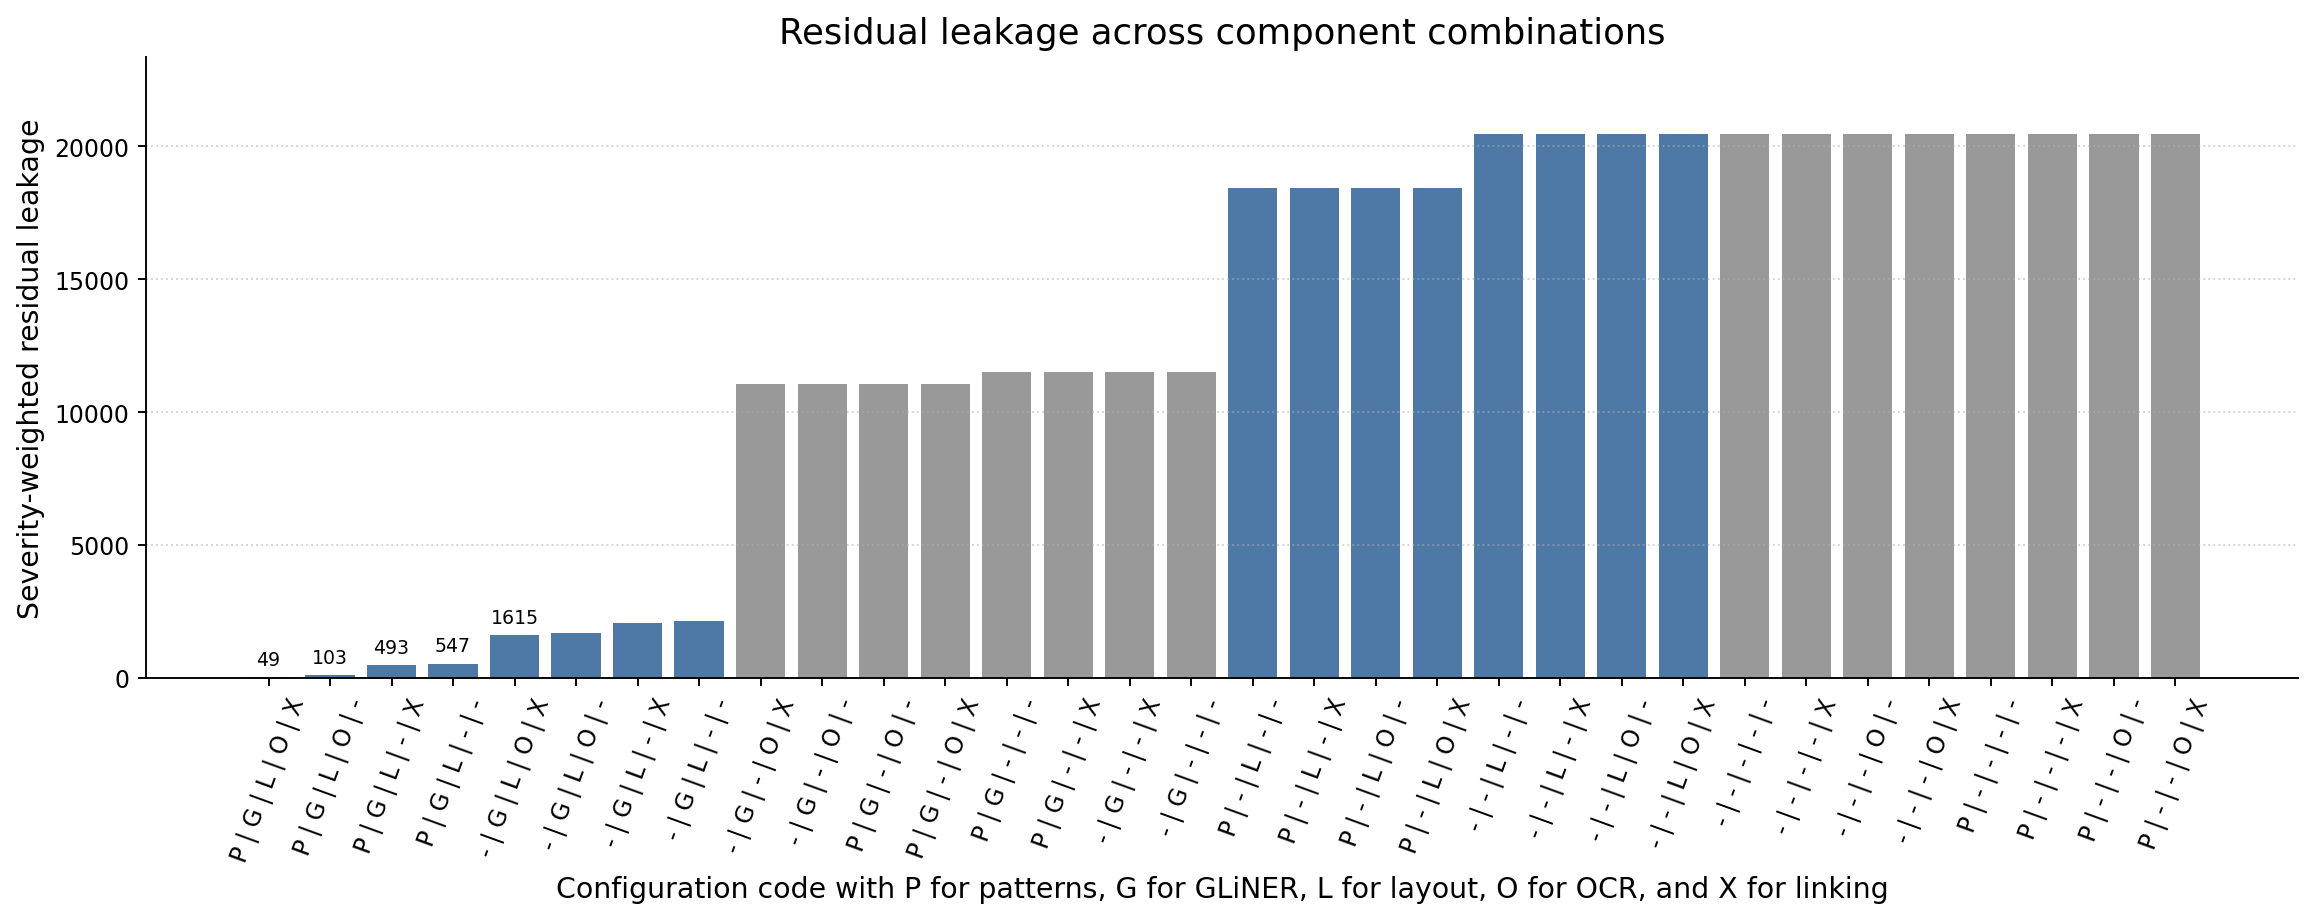

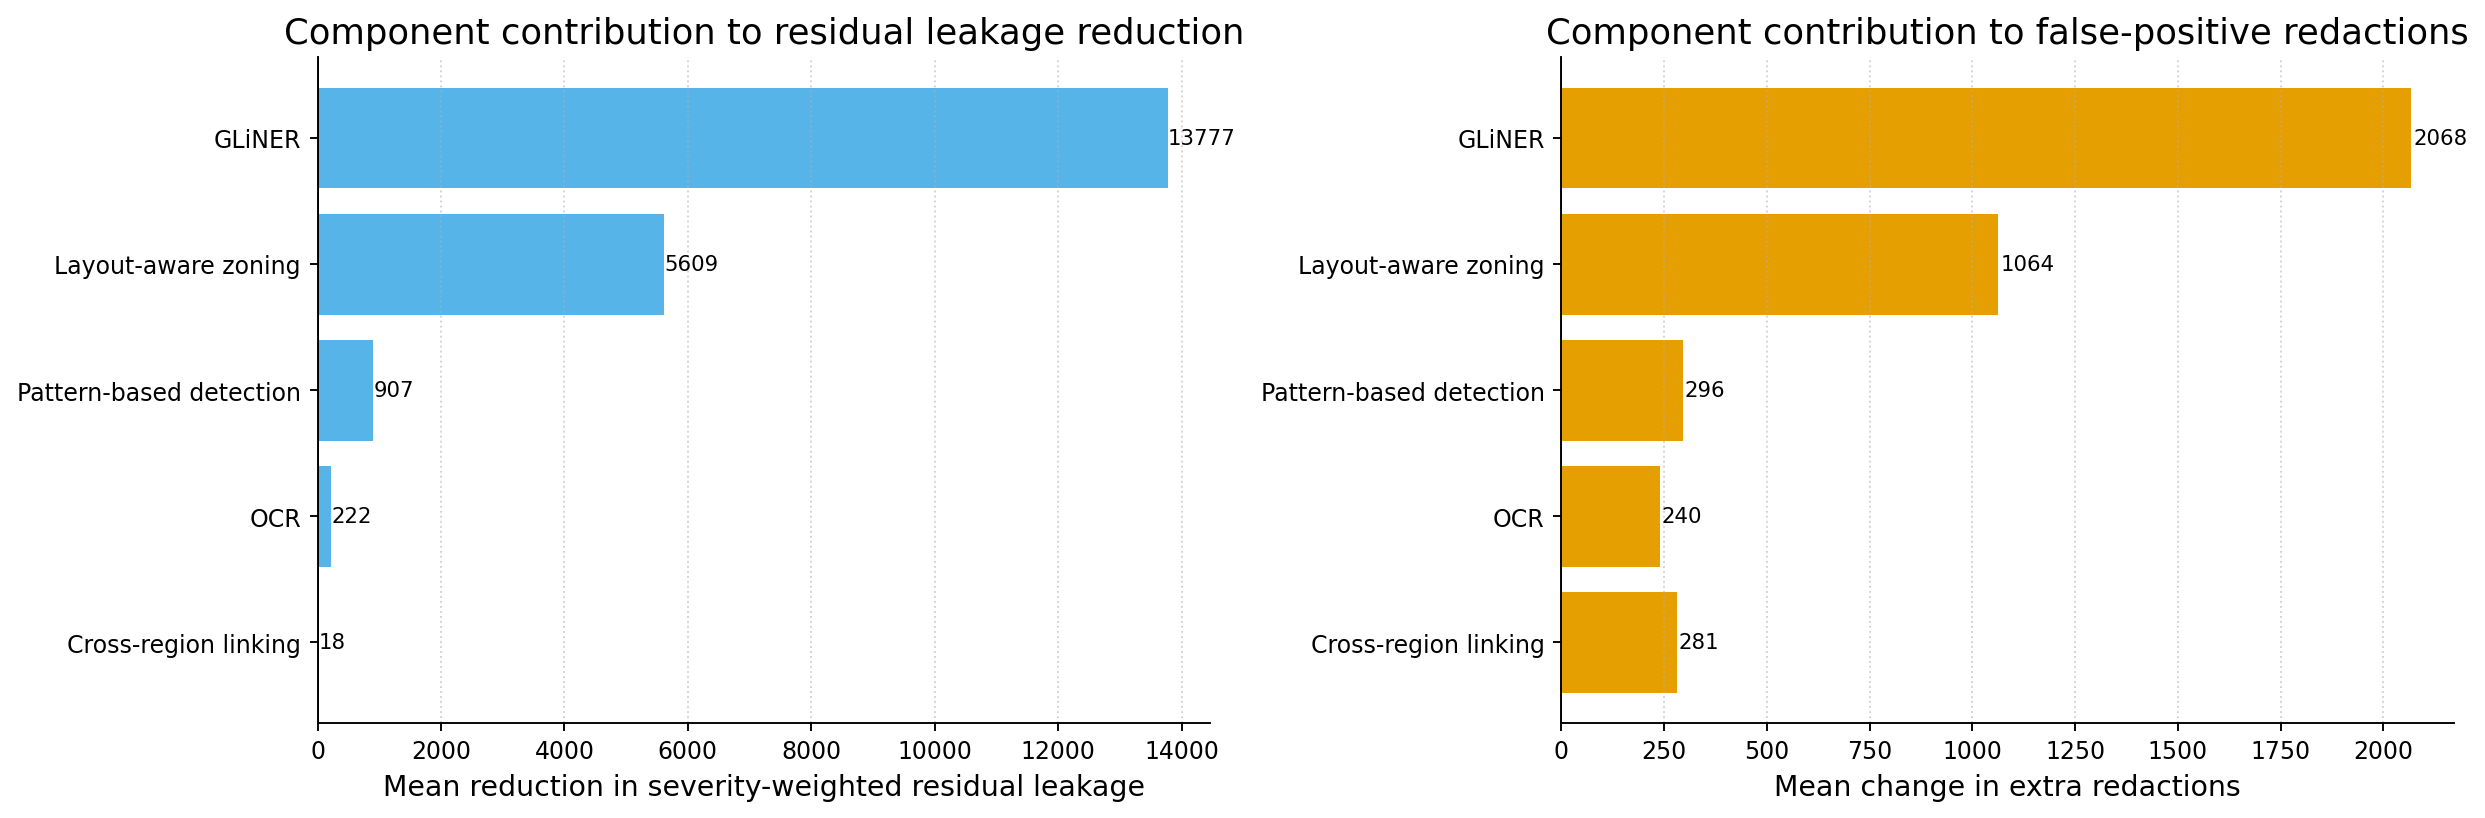

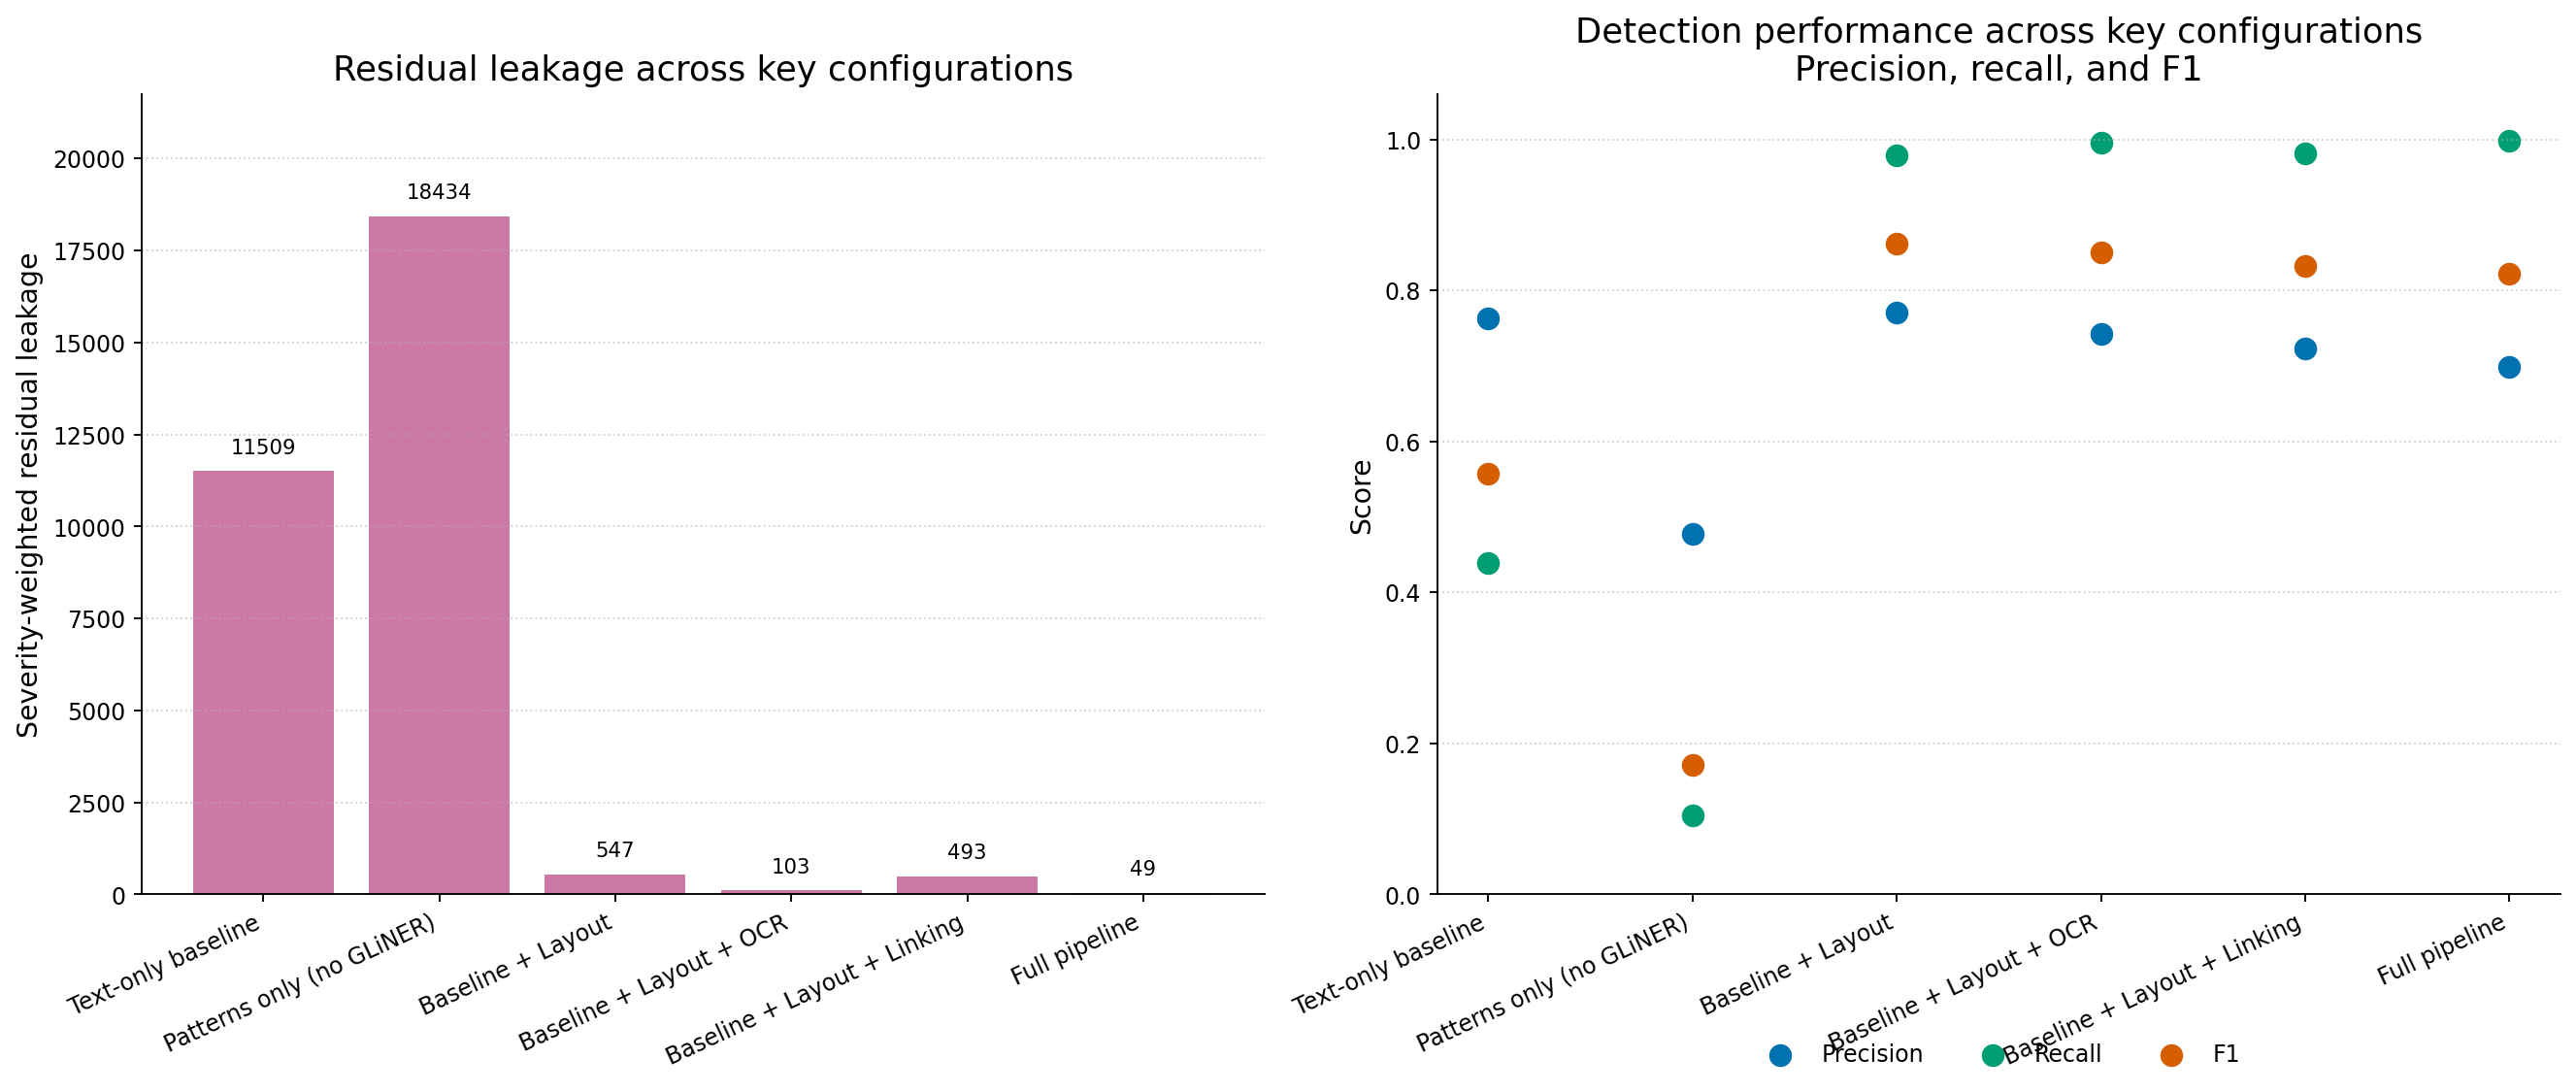

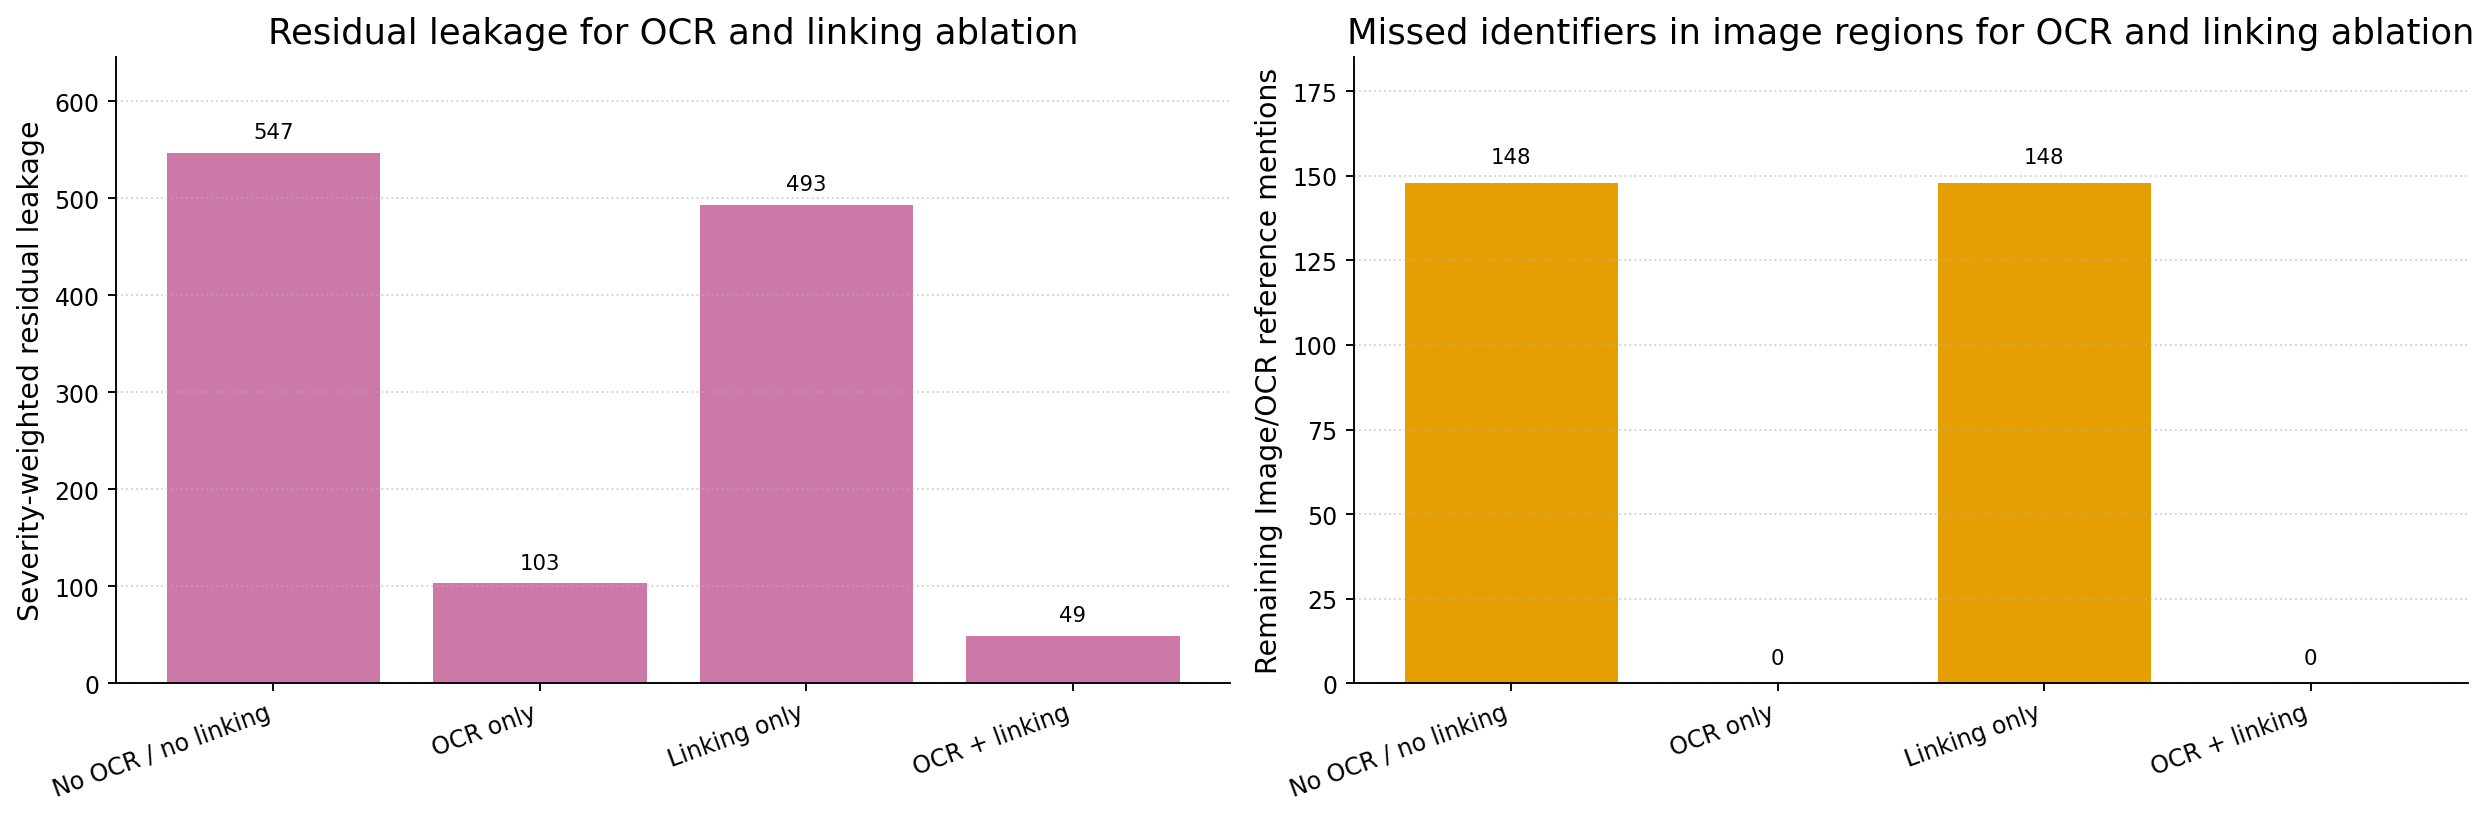

### OCR and linking comparison

,target_variant,code,precision,recall,f1,extra_redactions,remaining_reference_mentions,severity_weighted_residual_leakage,ocr_precision,ocr_recall,ocr_f1,ocr_remaining_reference_mentions
3,No OCR / no linking,P | G | L | - | -,0.771,0.978,0.862,2549,189,547.0,0.000,0.0,0.000,148
1,OCR only,P | G | L | O | -,0.742,0.995,0.850,3029,41,103.0,0.236,1.0,0.381,0
2,Linking only,P | G | L | - | X,0.723,0.981,0.833,3288,166,493.0,0.000,0.0,0.000,148
0,OCR + linking,P | G | L | O | X,0.699,0.998,0.822,3768,18,49.0,0.236,1.0,0.381,0


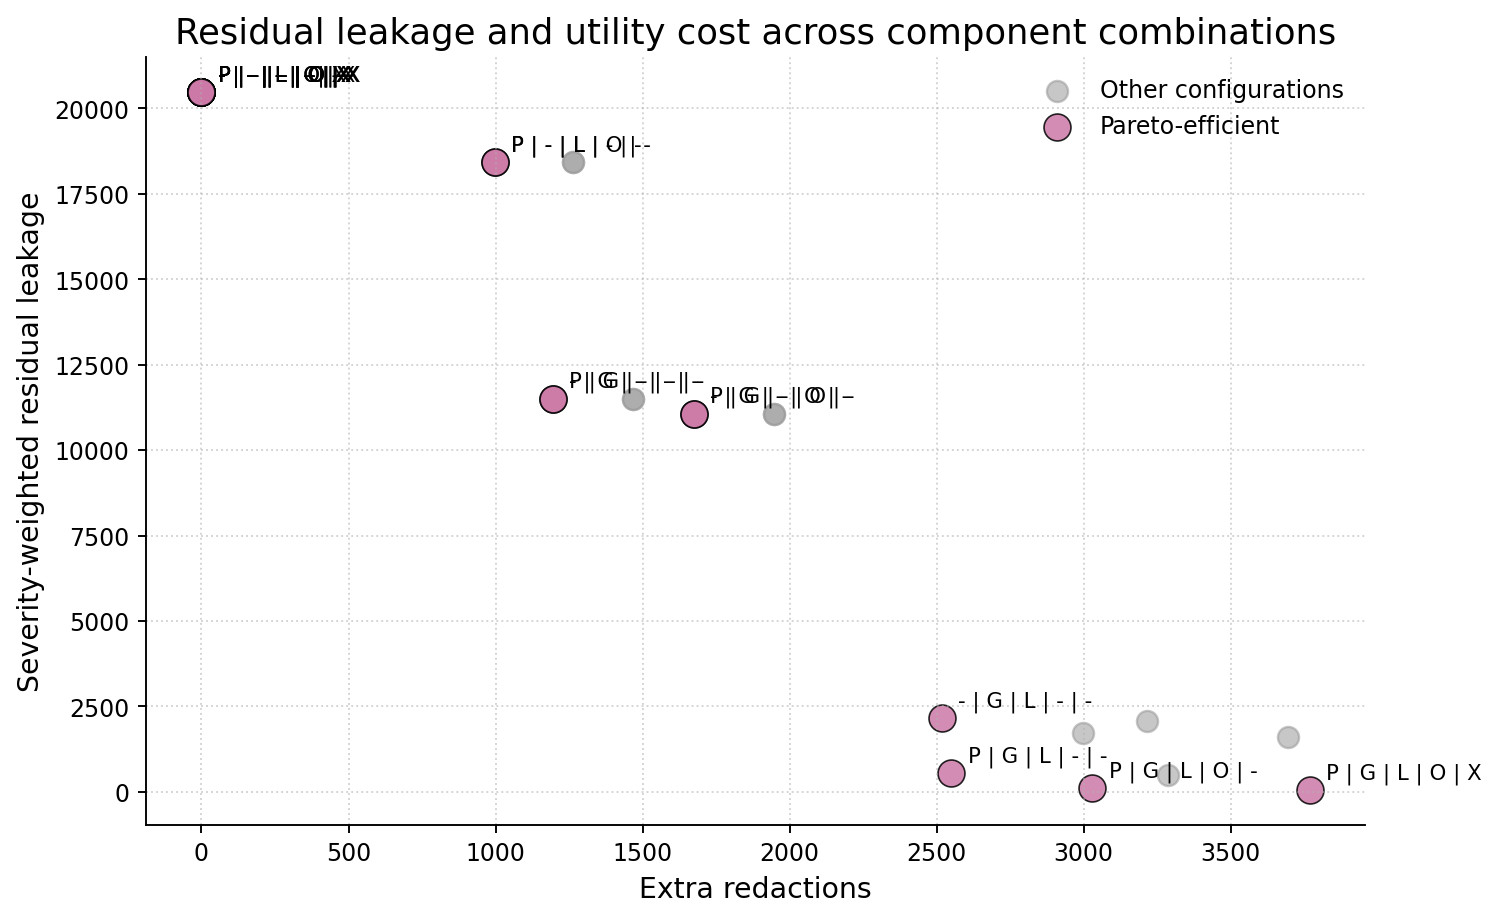

In [12]:

plot_full_grid_leakage(grid_df)

plot_component_effects(effect_summary_df)

plot_key_configurations(key_df)

ocr_link_df = plot_ocr_linking_ablation(grid_df)

display(Markdown("### OCR and linking comparison"))
display(ocr_link_df[[
    "target_variant",
    "code",
    "precision",
    "recall",
    "f1",
    "extra_redactions",
    "remaining_reference_mentions",
    "severity_weighted_residual_leakage",
    "ocr_precision",
    "ocr_recall",
    "ocr_f1",
    "ocr_remaining_reference_mentions",
]].round(3))

plot_privacy_utility_tradeoff(grid_df)


## Per-detector attribution within the joint pipeline (appendix material)

Each detection produced by the full RQ1 pipeline carries a `source` field that records which component fired (`pattern_*`, `ner_candidate_model`, `ner_gliner`, `ner_heuristic`, `ocr_*`, or a `_linked` variant propagated by `link_repeated_mentions`). Aggregating those tags against the gold annotations gives a per-source breakdown of **TP**, **FP**, and **Unique TP** (gold mentions caught by exactly one source family). The combined-pipeline row sums these into the joint TP / FP / FN that the rest of the chapter reports.

> **Limitation.** These numbers describe the marginal contribution of each detector inside the joint pipeline rather than its standalone performance, which would require an additional ablation we do not run here.

The next cell re-runs detection on the RQ1 test split once (no defender output is written; this is detection only) and prints the table. Run it after the main RQ2 grid; it reuses the trained candidate-name model written by RQ1.

In [13]:
from collections import Counter, defaultdict
from pathlib import Path
import pandas as pd

from thesis_project.dataset import DatasetManager
from thesis_project.experiments import Experiments
from thesis_project.shared import Config, canon
from thesis_project.defender.pipeline import detect_entities

# Repo root, resilient to where the notebook was launched from.
ROOT = Path.cwd()
while not (ROOT / "thesis_project").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
DATASET_ROOT_ATTR = ROOT / "notebooks" / "workspace" / "dataset"
MODEL_PATH_ATTR = ROOT / "notebooks" / "workspace" / "tuned_models" / "name_candidate_model.joblib"

dm_attr = DatasetManager(DATASET_ROOT_ATTR)
cfg_attr = Config(
    patterns=True, ner=True, ocr=True, strict=True, link=True,
    direct=True, quasi=True,
    labels=("Course code", "Group label", "Programme", "Date", "Role"),
    candidate=str(MODEL_PATH_ATTR) if MODEL_PATH_ATTR.exists() else None,
)
exp_attr = Experiments(DATASET_ROOT_ATTR, cfg_attr)
test_docs_attr = exp_attr.rq1_documents()


def source_family(src):
    """Group raw detector source tags into reporting families."""
    s = str(src or "").lower()
    if s.endswith("_linked"):     return "Linked propagation"
    if "candidate_model" in s:    return "Candidate-name model"
    if "gliner" in s:             return "GLiNER"
    if "heuristic" in s:          return "Heuristic NER"
    if s.startswith("pattern_"):  return "Patterns (regex)"
    if s.startswith("ocr"):       return "OCR"
    return "Other"


tp_per = Counter()
fp_per = Counter()
unique_per = Counter()
gold_total = 0
gold_caught = 0

for rec in test_docs_attr:
    doc = dm_attr.attach(rec)
    gold = dm_attr.load_annotations(doc)
    gold_keys = set()
    for ent in (gold.get("text_entities", []) or []) + (gold.get("ocr_entities", []) or []):
        label = canon(ent.get("label", ""))
        gold_keys.add((
            label,
            ent.get("path", ""),
            int(ent.get("start", 0) or 0),
            int(ent.get("end", 0) or 0),
        ))
    gold_total += len(gold_keys)

    detections = detect_entities(doc, cfg_attr)
    catchers = defaultdict(set)
    for det in detections:
        if getattr(det, "metadata", {}).get("eval_only"):
            continue
        fam = source_family(det.source)
        key = (canon(det.label), det.path, det.start, det.end)
        if key in gold_keys:
            tp_per[fam] += 1
            catchers[key].add(fam)
        else:
            fp_per[fam] += 1

    gold_caught += len(catchers)
    for fams in catchers.values():
        if len(fams) == 1:
            unique_per[next(iter(fams))] += 1

families = sorted(set(tp_per) | set(fp_per) | set(unique_per))
rows = []
for fam in families:
    tp = tp_per[fam]
    fp = fp_per[fam]
    rows.append({
        "Source family": fam,
        "TP": tp,
        "FP": fp,
        "Unique TP (only this source)": unique_per[fam],
        "Precision (per source)": round(tp / max(1, tp + fp), 3),
    })

attribution_df = pd.DataFrame(rows).sort_values("TP", ascending=False).reset_index(drop=True)
attribution_df.loc[len(attribution_df)] = {
    "Source family": "Combined pipeline",
    "TP": gold_caught,
    "FP": sum(fp_per.values()),
    "Unique TP (only this source)": sum(unique_per.values()),
    "Precision (per source)": round(gold_caught / max(1, gold_caught + sum(fp_per.values())), 3),
}
attribution_df["Total gold mentions"] = gold_total
attribution_df["Combined FN (missed by every source)"] = gold_total - gold_caught

print(f"Test documents: {len(test_docs_attr)}   "
      f"Gold mentions: {gold_total}   "
      f"Caught by at least one source: {gold_caught}   "
      f"Missed by every source (FN): {gold_total - gold_caught}")
attribution_df

Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 14334.60it/s]
Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.
Using CPU. Note: This module is much faster with a GPU.


Test documents: 84   Gold mentions: 8648   Caught by at least one source: 913   Missed by every source (FN): 7735


,Source family,TP,FP,Unique TP (only this source),Precision (per source),Total gold mentions,Combined FN (missed by every source)
0,Patterns (regex),913,646,913,0.586,8648,7735
1,Candidate-name model,0,1945,0,0.000,8648,7735
2,GLiNER,0,2277,0,0.000,8648,7735
3,Linked propagation,0,742,0,0.000,8648,7735
4,OCR,0,160,0,0.000,8648,7735
5,Combined pipeline,913,5770,913,0.137,8648,7735
